# 05 · Phase 1 vs Phase 2: ablation, comparison and error analysis

**Indoor Location Prediction Using Wi-Fi Signals** (Project 9) · Team T084 · Phase 2

The ablation study of the network, the comparison of all Phase 1 and Phase 2 models on the same
test set, and where the errors are (floor confusion matrices, error maps, phones). All numbers are
read from results/ (Phase 1) and results/phase2/ (Phase 2); no model is trained here.

## 1. Ablation study

**What:** the tuned hybrid multi-task network, and five variants that each change one thing,
scored with the same user-group folds and settings.

**Why:** an ablation shows which parts of the design really help. Folds differ in difficulty, so
we also count in how many of the 5 folds a variant is worse than the full network.

**Result:** the hybrid MLP reaches 9.21 m (floor accuracy
78.8%). Trained with 3 seeds, its CV error is
9.12 ± 0.11 m; every row is one run, so the
difference of two rows moves by about 0.16 m by chance. One
change at a time:
- three single-task networks: 8.90 m (-0.30 m, better; worse in 0 of 5 folds)
- no Phase 1 features: 9.17 m (-0.04 m, better; worse in 2 of 5 folds)
- no heard indicators: 9.79 m (+0.58 m, worse; worse in 4 of 5 folds)
- no hidden WAPs: 9.37 m (+0.16 m, worse; worse in 4 of 5 folds)
- no dropout, no weight decay: 10.28 m (+1.08 m, worse; worse in 5 of 5 folds)

,seed,building_acc,floor_acc,mean_2d
0,43,0.9961,0.7880,9.2053
1,44,0.9947,0.7928,8.9873
2,45,0.9954,0.8110,9.1553
3,mean,0.9954,0.7973,9.1160
4,std,0.0007,0.0122,0.1142


,label,building_acc,floor_acc,mean_2d,change_mean_2d,folds_worse
0,Hybrid MLP,0.996117,0.787961,9.205344,0.000000,0
1,three single-task networks,0.997495,0.847597,8.902727,-0.302617,0
2,no Phase 1 features,0.997851,0.794584,9.169518,-0.035825,2
3,no heard indicators,0.997267,0.846102,9.788529,0.583185,4
4,no hidden WAPs,0.998797,0.804606,9.369227,0.163883,4
5,"no dropout, no weight decay",0.990181,0.827497,10.284359,1.079015,5


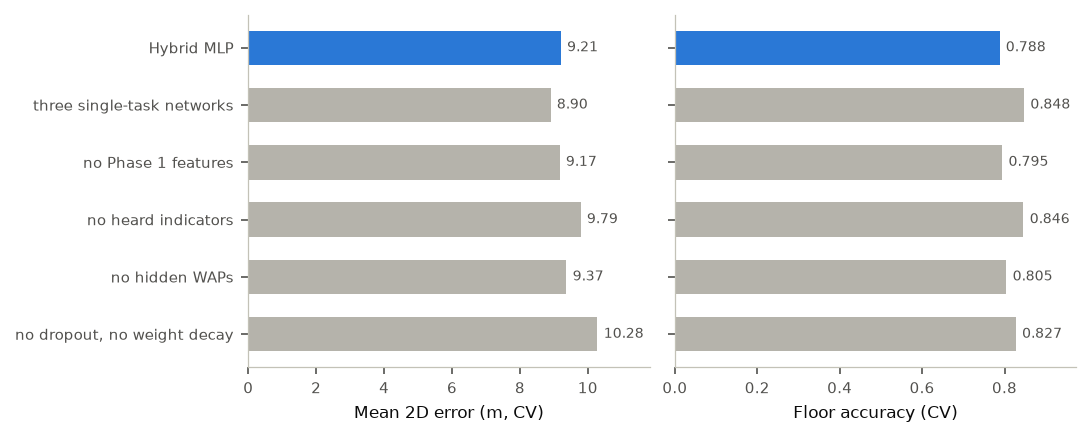

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from indoorloc import config, plots

plt.rcParams["figure.dpi"] = 150  # larger figures in the notebook
phase1, phase2 = config.RESULTS_DIR, config.RESULTS_DIR / "phase2"
ablation = pd.read_csv(phase2 / "metrics" / "ablation.csv")
fig = plots.ablation(ablation)
display(pd.read_csv(phase2 / "metrics" / "cv_seeds.csv").round(4))  # CV of the full network
ablation[["label", "building_acc", "floor_acc", "mean_2d", "change_mean_2d", "folds_worse"]]

## 2. The final network

**What:** the three networks that are tested on the test set, with their CV scores, and our rule,
fixed before the test set was used: the final network is the hybrid multi-task network (the
brief's design: one shared trunk, three heads), with the setting of lowest CV mean 2D error.

**Why:** as in Phase 1, nothing is chosen on the test set; the plain MLP and the single-task
networks are tested next to it to show what the hybrid inputs and the shared trunk change.

**Result:** CV mean 2D error MLP 9.17 m, Hybrid single-task MLPs 8.90 m, Hybrid MLP 9.21 m;
final network: **Hybrid MLP**.

In [2]:
final = json.loads((phase2 / "metrics" / "final_model.json").read_text())
print(f"Rule: {final['rule']} -> {final['name']}")
pd.DataFrame({key: final[key] for key in ["cv_building_acc", "cv_floor_acc", "cv_mean_2d"]})

Rule: fixed before the test set was used: the hybrid multi-task network (one shared trunk, three heads), with the setting of lowest CV mean 2D error; the other candidates are tested next to it -> Hybrid MLP


,cv_building_acc,cv_floor_acc,cv_mean_2d
mlp,0.9979,0.7946,9.1695
hybrid_single,0.9975,0.8476,8.9027
hybrid_mlp,0.9961,0.7880,9.2053


## 3. Test set: Phase 1 vs Phase 2

**What:** building and floor accuracy, mean absolute error (MAE) of x and y, and mean and median
2D error of all eight models (four from Phase 1, three networks and the blend) on the same
1,111 test scans, each tested once.

**Why:** the brief asks for an AML vs DL comparison on the same split with the same metrics.

**Result:** Hybrid MLP: building 99.9%, floor 90.8%, mean 2D error
8.32 m (median 6.10 m), against 7.42 m for Phase 1's Random Forest
(floor 92.2%) and 95.2% of floors for XGBoost.

,model,name,phase,building_acc,floor_acc,mae_x,mae_y,mean_2d,median_2d
0,baseline_rf,Baseline RF,1,0.9982,0.9118,8.6817,7.3997,12.5188,7.7044
1,knn,kNN,1,0.9982,0.8749,6.1224,5.7046,9.2212,5.8812
2,rf,Random Forest,1,1.0000,0.9217,4.7738,4.6393,7.4185,5.3402
3,xgb,XGBoost,1,1.0000,0.9523,5.1833,4.7663,7.8633,6.1854
4,mlp,MLP,2,1.0000,0.9091,5.7159,5.1123,8.4372,6.3335
5,hybrid_single,Hybrid single-task MLPs,2,1.0000,0.9415,5.3980,4.9269,8.0323,5.7471
6,hybrid_mlp,Hybrid MLP,2,0.9991,0.9082,5.6387,5.0578,8.3249,6.1012
7,blend,Blend: Random Forest + Hybrid MLP,2,1.0000,0.9217,5.4621,4.9345,8.0979,5.9232


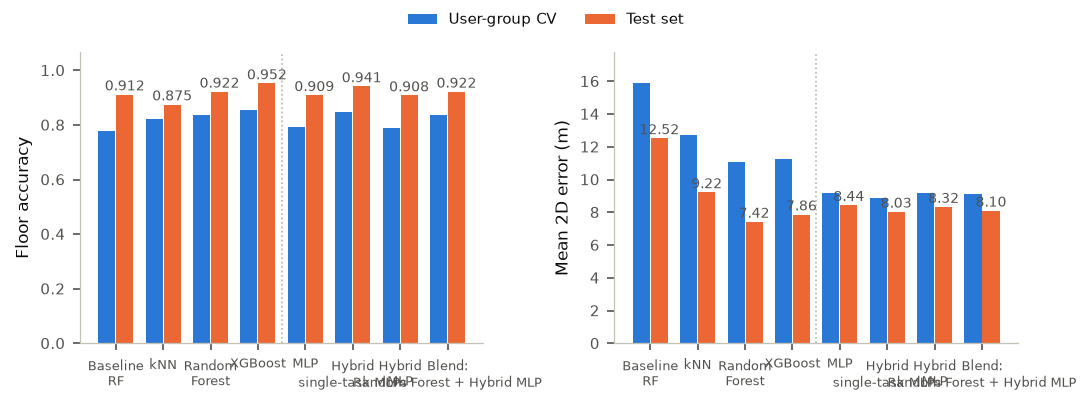

In [3]:
comparison = pd.read_csv(phase2 / "metrics" / "comparison.csv")
cv = comparison[["model", "name", "building_acc_cv", "floor_acc_cv", "mean_2d_cv"]]
test = comparison.drop(columns=["building_acc_cv", "floor_acc_cv", "mean_2d_cv"])
labels = [name.replace(" ", "\n", 1) for name in comparison["name"]]
fig = plots.model_comparison(
    cv.set_axis(["model", "name", "building_acc", "floor_acc", "mean_2d"], axis=1),
    test,
    names=labels,
    split=int((comparison["phase"] == 1).sum()),
)
test.round(4)

## 4. The hybrid blend: Random Forest + network

**What:** every training scan gets a prediction from a Random Forest and from a network that did
not see it (out-of-fold, user-group CV). For every forest weight w from 0 to 1, the blend averages
w × forest + (1 - w) × network (probabilities for building and floor, positions for x and y), and
each task keeps the weight with the best CV score.

**Why:** trees and networks make different kinds of mistakes, and in Phase 1 no model was best at
every task, so an average can beat both. Choosing w by CV keeps the test set out of it.

**Result:** CV chose w = 0.8 for building, 1 for floor and
0.1 for position. In CV the blend reaches 83.6% of floors and
9.14 m, against 78.8% and 9.21 m for the network alone.
On the test set: 92.2% of floors and 8.10 m (network:
90.8%, 8.32 m; Random Forest: 92.2%, 7.42 m).

In [4]:
blend = json.loads((phase2 / "tuning" / "blend.json").read_text())
print("forest weight per task:", blend["forest_weights"])
pd.read_csv(phase2 / "tuning" / "blend.csv").round(4)

forest weight per task: {'building': 0.8, 'floor': 1.0, 'position': 0.1}


,forest_weight,building_acc,floor_acc,mean_2d,chosen_building,chosen_floor,chosen_position
0,0.0,0.9961,0.7880,9.2053,False,False,False
1,0.1,0.9961,0.7909,9.1410,False,False,True
2,0.2,0.9963,0.7939,9.1459,False,False,False
3,0.3,0.9964,0.7976,9.2091,False,False,False
4,0.4,0.9967,0.8021,9.3277,False,False,False
5,0.5,0.9971,0.8074,9.5005,False,False,False
6,0.6,0.9978,0.8214,9.7250,False,False,False
7,0.7,0.9978,0.8324,9.9961,False,False,False
8,0.8,0.9978,0.8323,10.3133,True,False,False
9,0.9,0.9972,0.8343,10.6776,False,False,False


## 5. Hierarchical error breakdown

**What:** the test scans of the final network and of Phase 1's Random Forest split into three
cases (building wrong / building right, floor wrong / both right), with each case's share of scans,
mean 2D error and share of the total error.

**Why:** the brief asks for a hierarchical error breakdown: it shows whether errors come from the
wrong building, the wrong floor, or the position on the right floor.

**Result:** the network gets the building wrong for 1 of the 1,111 scans and the
floor wrong for 9.1% of them (Random Forest:
7.8%); 85.4% of its total error is on scans with
building and floor right (Random Forest: 86.2%).

In [5]:
final_key = final["final_model"]
for name, folder, key in (("Phase 2", phase2, final_key), ("Phase 1", phase1, "rf")):
    table = pd.read_csv(folder / "metrics" / "error_breakdown.csv")
    print(name, key)
    display(table[table["model"] == key].round(4))

Phase 2 hybrid_mlp


,model,case,n_scans,share_of_scans,mean_2d,share_of_error
6,hybrid_mlp,building wrong,1,0.0009,39.8037,0.0043
7,hybrid_mlp,"building right, floor wrong",101,0.0909,12.9368,0.1413
8,hybrid_mlp,both right,1009,0.9082,7.8321,0.8544


Phase 1 rf


,model,case,n_scans,share_of_scans,mean_2d,share_of_error
6,rf,building wrong,0,0.0000,NaN,0.0000
7,rf,"building right, floor wrong",87,0.0783,13.0604,0.1379
8,rf,both right,1024,0.9217,6.9391,0.8621


## 6. Floor confusion matrices

**What:** true against predicted floor, per building, for the final network (first figure) and
for Phase 1's Random Forest (second figure); colors show the share of each true floor's scans.

**Why:** the brief asks for floor confusion matrices; they show which floors are mixed up.

**Result:** the network gets 102 test scans' floors wrong, and 100 of these mistakes are one floor
off: neighboring floors hear similar WAPs.

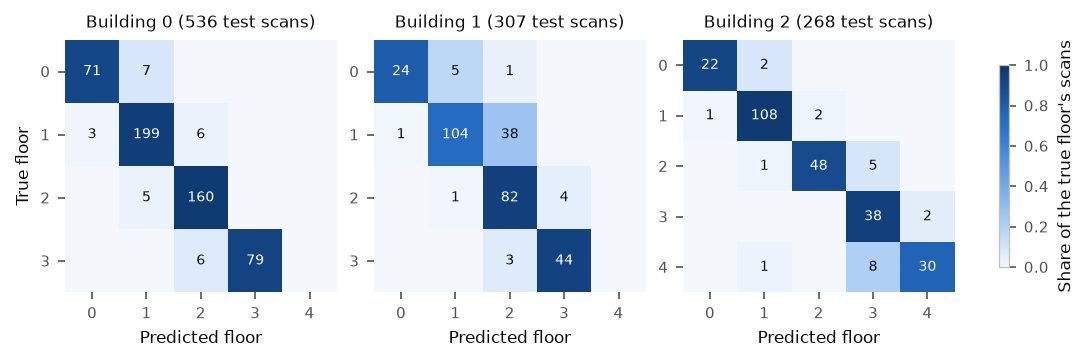

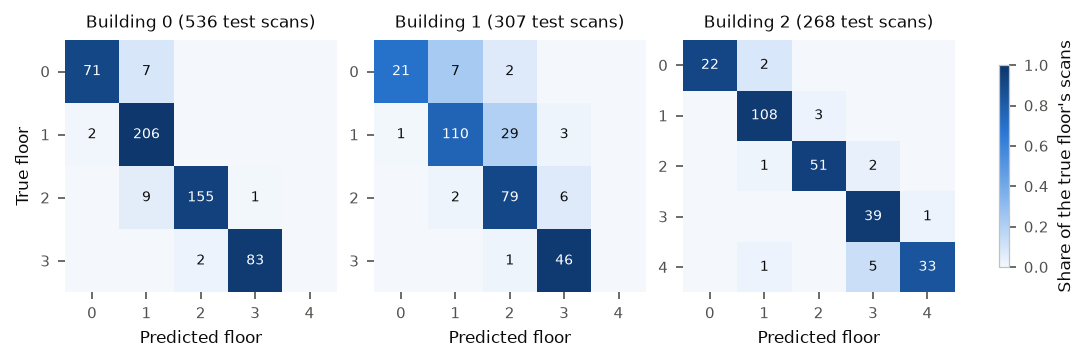

In [6]:
fig_dl = plots.floor_confusion(pd.read_csv(phase2 / "metrics" / "floor_confusion.csv"))
fig_rf = plots.floor_confusion(pd.read_csv(phase1 / "metrics" / "floor_confusion.csv"))

## 7. Coordinate error maps

**What:** true test positions (gray) and predicted positions colored by their 2D error, per
building, for the final network (first figure) and Phase 1's Random Forest (second figure).

**Why:** the brief asks for coordinate error maps; they show where on the campus the large errors
are.

**Result:** the network puts 41.8% of the test scans within 5 m and 71.2% within
10 m (Random Forest: 47.7% and 76.0%).

network: within 5 m 41.8%, within 10 m 71.2%
Random Forest: within 5 m 47.7%, within 10 m 76.0%


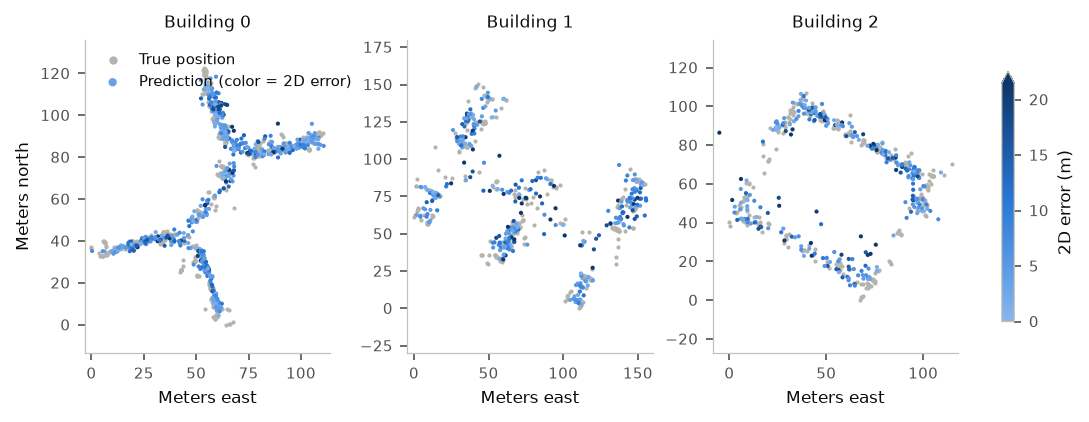

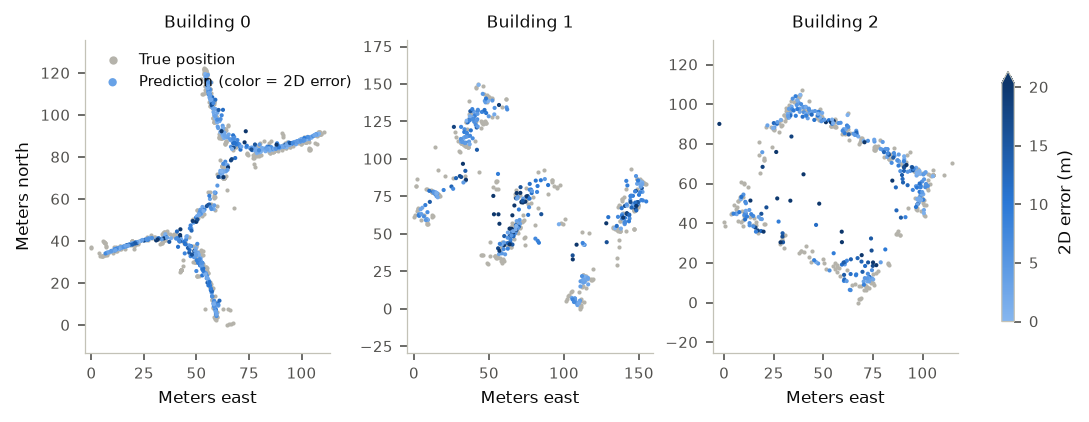

In [7]:
dl_predictions = pd.read_csv(phase2 / "predictions" / f"{final_key}.csv")
rf_predictions = pd.read_csv(phase1 / "predictions" / "rf.csv")
fig_dl_map = plots.error_map(dl_predictions)
fig_rf_map = plots.error_map(rf_predictions)
for name, table in (("network", dl_predictions), ("Random Forest", rf_predictions)):
    errors = table["err_2d"]
    print(f"{name}: within 5 m {(errors <= 5).mean():.1%}, within 10 m {(errors <= 10).mean():.1%}")

## 8. Seen and new phones

**What:** floor accuracy and mean 2D error on test scans from phones seen in training and from new
phones, for the final network and Phase 1's Random Forest.

**Why:** the brief asks us to keep the phone ids for a robustness check: most test scans come from
phones the models never saw.

**Result:** the network's error is 6.62 m on seen phones and
9.27 m on new ones (Random Forest: 5.84 m and
8.30 m).

In [8]:
for name, folder, key in (("Phase 2", phase2, final_key), ("Phase 1", phase1, "rf")):
    table = pd.read_csv(folder / "metrics" / "per_phone.csv")
    print(name, key)
    display(table[table["model"] == key].round(4))

Phase 2 hybrid_mlp


,model,phones,n_phones,n_scans,floor_acc,mean_2d
4,hybrid_mlp,seen in training,2,397,0.9345,6.6211
5,hybrid_mlp,new,9,714,0.8936,9.2723


Phase 1 rf


,model,phones,n_phones,n_scans,floor_acc,mean_2d
4,rf,seen in training,2,397,0.9370,5.8350
5,rf,new,9,714,0.9132,8.2989


## 9. Seed check

**What:** the final network trained again with 5 random seeds (they change the starting
weights, the order of the mini-batches and the hidden WAPs) and tested each time.

**Why:** a network's score depends a little on chance; the spread over seeds shows how much.

**Result:** mean 2D error 8.21 ± 0.06 m and floor accuracy 91.7% ±
0.7 points (mean ± standard deviation over the seeds).

In [9]:
pd.read_csv(phase2 / "metrics" / "seeds.csv").round(4)

,seed,building_acc,floor_acc,mae_x,mae_y,mean_2d,median_2d
0,42,0.9991,0.9082,5.6387,5.0578,8.3249,6.1012
1,43,0.9991,0.9181,5.5334,4.9089,8.1688,5.9629
2,44,0.9991,0.9280,5.6106,4.9292,8.2132,6.0049
3,45,0.9991,0.9127,5.5513,4.9118,8.1800,5.9933
4,46,0.9991,0.9172,5.6010,4.8995,8.1877,5.9049
5,mean,0.9991,0.9168,5.5870,4.9415,8.2149,5.9935
6,std,0.0000,0.0074,0.0435,0.0660,0.0636,0.0716


## Summary

- The ablation study shows which parts of the hybrid multi-task network help (section 1); every
  variant was scored on the same user-group folds as Phase 1.
- On the test set, Hybrid MLP reaches 90.8% floor accuracy and a mean 2D error of
  8.32 m, against 7.42 m for Phase 1's Random Forest; over 5 seeds,
  8.21 ± 0.06 m.
- The blend of the Random Forest and the network, with weights chosen by CV, reaches
  92.2% of floors and 8.10 m on the test set.
- Errors stay mostly on the right floor (85.4% of the total error), and new phones
  remain harder than seen ones.